In [2]:
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 
import numpy as np 

# Sales Data Exploratory Data Analysis

## Project Overview

This project explores sales data to identify patterns in customer segments, regional performance, payment methods, product categories, profitability, and sales trends.

## Objectives
- Explore the dataset and assess its quality.
- Analyze customer and sales patterns.
- Visualize relationships between important variables.
- Investigate sales, discounts, profits, and returns.
- Summarize key findings from the analysis.

In [3]:
pd.set_option('display.max_columns',None)

In [4]:
df = pd.read_csv("sales_data.csv")

In [5]:
df.head()

,Order_ID,Order_Date,Customer_ID,Region,City,Segment,Channel,Category,Subcategory,Product_ID,Quantity,Unit_Price_INR,Discount,Sales_INR,Discount_Amount_INR,Net_Sales_INR,Cost_INR,Profit_INR,Shipping_Days,Returned,Customer_Satisfaction,Payment_Method
0,ORD111444,2024-01-01,CUST10128,West,Pune,Corporate,Online,Home & Kitchen,Appliances,P1046,2,327.15,0.00,654.30,0.00,654.30,387.43,266.87,1,No,4,Debit Card
1,ORD102034,2024-01-01,CUST10316,West,Ahmedabad,Corporate,Online,Beauty,Personal Care,P1048,1,1711.99,0.10,1711.99,171.20,1540.79,874.52,666.27,6,No,3,UPI
2,ORD106623,2024-01-01,CUST11764,South,Chennai,Consumer,Online,Home & Kitchen,Cookware,P1066,5,1180.95,0.05,5904.75,295.24,5609.51,3095.78,2513.74,3,No,3,Net Banking
3,ORD113951,2024-01-01,CUST12447,Central,Raipur,Consumer,Online,Home & Kitchen,Decor,P1057,2,703.24,0.15,1406.48,210.97,1195.51,720.77,474.74,4,No,3,Net Banking
4,ORD105177,2024-01-01,CUST10691,North,Chandigarh,Consumer,Online,Home & Kitchen,Decor,P1023,4,380.55,0.15,1522.20,228.33,1293.87,820.70,473.17,6,No,3,Credit Card


In [6]:
df.tail()

,Order_ID,Order_Date,Customer_ID,Region,City,Segment,Channel,Category,Subcategory,Product_ID,Quantity,Unit_Price_INR,Discount,Sales_INR,Discount_Amount_INR,Net_Sales_INR,Cost_INR,Profit_INR,Shipping_Days,Returned,Customer_Satisfaction,Payment_Method
14995,ORD109942,2025-12-31,CUST10397,West,Pune,Consumer,Online,Beauty,Skincare,P1004,6,2468.89,0.20,14813.34,2962.67,11850.67,5930.88,4262.25,4,Yes,3,Debit Card
14996,ORD101325,2025-12-31,CUST11524,South,Bengaluru,Consumer,Retail Store,Technology,Accessories,P1013,4,713.40,0.00,2853.60,0.00,2853.60,1985.23,868.37,5,No,3,Debit Card
14997,ORD107747,2025-12-31,CUST11321,East,Guwahati,Consumer,Online,Furniture,Chairs,P1022,2,1374.64,0.00,2749.28,0.00,2749.28,1795.97,953.31,2,No,3,Net Banking
14998,ORD105862,2025-12-31,CUST11426,East,Guwahati,Consumer,Online,Beauty,Personal Care,P1004,4,2504.95,0.25,10019.80,2504.95,7514.85,4022.03,3492.82,8,No,3,Credit Card
14999,ORD102445,2025-12-31,CUST10296,East,Kolkata,Consumer,Online,Office Supplies,Pens,P1055,7,833.00,0.30,5831.00,1749.30,4081.70,2212.60,1869.10,4,No,4,Credit Card


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Order_ID               15000 non-null  str    
 1   Order_Date             15000 non-null  str    
 2   Customer_ID            15000 non-null  str    
 3   Region                 15000 non-null  str    
 4   City                   15000 non-null  str    
 5   Segment                15000 non-null  str    
 6   Channel                15000 non-null  str    
 7   Category               15000 non-null  str    
 8   Subcategory            15000 non-null  str    
 9   Product_ID             15000 non-null  str    
 10  Quantity               15000 non-null  int64  
 11  Unit_Price_INR         15000 non-null  float64
 12  Discount               15000 non-null  float64
 13  Sales_INR              15000 non-null  float64
 14  Discount_Amount_INR    15000 non-null  float64
 15  Net_Sales_INR

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df['Order_ID'].duplicated().sum()

np.int64(0)

In [10]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'])

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Order_ID               15000 non-null  str           
 1   Order_Date             15000 non-null  datetime64[us]
 2   Customer_ID            15000 non-null  str           
 3   Region                 15000 non-null  str           
 4   City                   15000 non-null  str           
 5   Segment                15000 non-null  str           
 6   Channel                15000 non-null  str           
 7   Category               15000 non-null  str           
 8   Subcategory            15000 non-null  str           
 9   Product_ID             15000 non-null  str           
 10  Quantity               15000 non-null  int64         
 11  Unit_Price_INR         15000 non-null  float64       
 12  Discount               15000 non-null  float64       
 13  Sales_INR   

In [12]:
df.head()

,Order_ID,Order_Date,Customer_ID,Region,City,Segment,Channel,Category,Subcategory,Product_ID,Quantity,Unit_Price_INR,Discount,Sales_INR,Discount_Amount_INR,Net_Sales_INR,Cost_INR,Profit_INR,Shipping_Days,Returned,Customer_Satisfaction,Payment_Method
0,ORD111444,2024-01-01,CUST10128,West,Pune,Corporate,Online,Home & Kitchen,Appliances,P1046,2,327.15,0.00,654.30,0.00,654.30,387.43,266.87,1,No,4,Debit Card
1,ORD102034,2024-01-01,CUST10316,West,Ahmedabad,Corporate,Online,Beauty,Personal Care,P1048,1,1711.99,0.10,1711.99,171.20,1540.79,874.52,666.27,6,No,3,UPI
2,ORD106623,2024-01-01,CUST11764,South,Chennai,Consumer,Online,Home & Kitchen,Cookware,P1066,5,1180.95,0.05,5904.75,295.24,5609.51,3095.78,2513.74,3,No,3,Net Banking
3,ORD113951,2024-01-01,CUST12447,Central,Raipur,Consumer,Online,Home & Kitchen,Decor,P1057,2,703.24,0.15,1406.48,210.97,1195.51,720.77,474.74,4,No,3,Net Banking
4,ORD105177,2024-01-01,CUST10691,North,Chandigarh,Consumer,Online,Home & Kitchen,Decor,P1023,4,380.55,0.15,1522.20,228.33,1293.87,820.70,473.17,6,No,3,Credit Card


In [13]:
df['Order_Date']

0       2024-01-01
1       2024-01-01
2       2024-01-01
3       2024-01-01
4       2024-01-01
           ...    
14995   2025-12-31
14996   2025-12-31
14997   2025-12-31
14998   2025-12-31
14999   2025-12-31
Name: Order_Date, Length: 15000, dtype: datetime64[us]

In [14]:
df.describe()

,Order_Date,Quantity,Unit_Price_INR,Discount,Sales_INR,Discount_Amount_INR,Net_Sales_INR,Cost_INR,Profit_INR,Shipping_Days,Customer_Satisfaction
count,15000,15000.000000,15000.00000,15000.000000,15000.000000,15000.00000,15000.000000,15000.000000,15000.000000,15000.000000,15000.00000
mean,2025-01-01 05:42:31.680000,3.991333,1347.45306,0.106630,5396.765599,578.66473,4818.100912,2960.555138,1818.571167,3.678133,3.54920
min,2024-01-01 00:00:00,1.000000,150.00000,0.000000,150.000000,0.00000,119.780000,75.110000,39.230000,1.000000,1.00000
25%,2024-07-01 00:00:00,2.000000,708.49000,0.050000,2033.355000,17.45500,1793.360000,1090.092500,663.167500,2.000000,3.00000
50%,2025-01-03 00:00:00,4.000000,1092.60500,0.100000,3901.345000,298.30500,3462.510000,2110.155000,1279.100000,4.000000,4.00000
75%,2025-07-05 00:00:00,6.000000,1692.42750,0.150000,6949.402500,745.05250,6230.482500,3812.557500,2334.192500,5.000000,4.00000
max,2025-12-31 00:00:00,7.000000,18616.06000,0.300000,130312.420000,13031.24000,117281.180000,70176.380000,47104.800000,8.000000,5.00000
std,NaN,1.993370,973.90804,0.087742,5225.206681,863.70892,4700.051718,2919.123008,1821.210884,1.669228,0.73522


In [15]:
df.isnull().sum()

Order_ID                 0
Order_Date               0
Customer_ID              0
Region                   0
City                     0
Segment                  0
Channel                  0
Category                 0
Subcategory              0
Product_ID               0
Quantity                 0
Unit_Price_INR           0
Discount                 0
Sales_INR                0
Discount_Amount_INR      0
Net_Sales_INR            0
Cost_INR                 0
Profit_INR               0
Shipping_Days            0
Returned                 0
Customer_Satisfaction    0
Payment_Method           0
dtype: int64

In [16]:
df['Order_Year'] = df['Order_Date'].dt.year

In [17]:
df['Order_month'] = df['Order_Date'].dt.month

In [18]:
df.head()

,Order_ID,Order_Date,Customer_ID,Region,City,Segment,Channel,Category,Subcategory,Product_ID,Quantity,Unit_Price_INR,Discount,Sales_INR,Discount_Amount_INR,Net_Sales_INR,Cost_INR,Profit_INR,Shipping_Days,Returned,Customer_Satisfaction,Payment_Method,Order_Year,Order_month
0,ORD111444,2024-01-01,CUST10128,West,Pune,Corporate,Online,Home & Kitchen,Appliances,P1046,2,327.15,0.00,654.30,0.00,654.30,387.43,266.87,1,No,4,Debit Card,2024,1
1,ORD102034,2024-01-01,CUST10316,West,Ahmedabad,Corporate,Online,Beauty,Personal Care,P1048,1,1711.99,0.10,1711.99,171.20,1540.79,874.52,666.27,6,No,3,UPI,2024,1
2,ORD106623,2024-01-01,CUST11764,South,Chennai,Consumer,Online,Home & Kitchen,Cookware,P1066,5,1180.95,0.05,5904.75,295.24,5609.51,3095.78,2513.74,3,No,3,Net Banking,2024,1
3,ORD113951,2024-01-01,CUST12447,Central,Raipur,Consumer,Online,Home & Kitchen,Decor,P1057,2,703.24,0.15,1406.48,210.97,1195.51,720.77,474.74,4,No,3,Net Banking,2024,1
4,ORD105177,2024-01-01,CUST10691,North,Chandigarh,Consumer,Online,Home & Kitchen,Decor,P1023,4,380.55,0.15,1522.20,228.33,1293.87,820.70,473.17,6,No,3,Credit Card,2024,1


In [19]:
df['Order_Year'].value_counts()

Order_Year
2025    7560
2024    7440
Name: count, dtype: int64

In [20]:
df['Order_month'].value_counts()

Order_month
1     1316
7     1300
3     1294
8     1283
10    1280
6     1252
4     1251
9     1247
5     1243
11    1227
12    1211
2     1096
Name: count, dtype: int64

In [21]:
df['Region'].value_counts()

Region
South      3561
West       3314
North      3217
Central    2489
East       2419
Name: count, dtype: int64

In [22]:
df['City'].value_counts()

City
Chennai        904
Bengaluru      904
Hyderabad      884
Mumbai         872
Kochi          869
Ahmedabad      838
Lucknow        832
Surat          818
Delhi          805
Jaipur         803
Pune           786
Chandigarh     777
Bhopal         652
Nagpur         650
Kolkata        622
Bhubaneswar    613
Patna          603
Indore         594
Raipur         593
Guwahati       581
Name: count, dtype: int64

In [23]:
df['Segment'].value_counts()

Segment
Consumer          8224
Corporate         3807
Small Business    2969
Name: count, dtype: int64

In [24]:
df['Channel'].value_counts()

Channel
Online          8700
Retail Store    3319
Marketplace     2981
Name: count, dtype: int64

In [25]:
df['Subcategory'].value_counts()

Subcategory
Laptops          1095
Accessories      1077
Phones           1040
Monitors         1019
Binders           884
Paper             867
Pens              823
Printers          784
Desks             740
Tables            716
Chairs            713
Storage           690
Appliances        680
Decor             657
Cookware          654
Cleaning          651
Personal Care     527
Skincare          477
Makeup            475
Haircare          431
Name: count, dtype: int64

In [26]:
df['Quantity'].value_counts()

Quantity
4    2203
5    2162
1    2156
6    2130
2    2127
3    2124
7    2098
Name: count, dtype: int64

In [27]:
df['Shipping_Days'].value_counts()

Shipping_Days
3    3639
4    3228
2    2558
5    2098
1    1285
6    1164
7     756
8     272
Name: count, dtype: int64

In [28]:
df['Customer_Satisfaction'].value_counts()

Customer_Satisfaction
4    6735
3    6106
5    1227
2     913
1      19
Name: count, dtype: int64

In [29]:
df['Payment_Method'].value_counts()

Payment_Method
UPI                 5299
Credit Card         3674
Debit Card          2508
Net Banking         2296
Cash on Delivery    1223
Name: count, dtype: int64

In [30]:
group_region = pd.DataFrame(df.groupby('Region')['City'].value_counts())

In [31]:
group_region

count
Region  City              
Central Bhopal         652
        Nagpur         650
        Indore         594
        Raipur         593
East    Kolkata        622
        Bhubaneswar    613
        Patna          603
        Guwahati       581
North   Lucknow        832
        Delhi          805
        Jaipur         803
        Chandigarh     777
South   Bengaluru      904
        Chennai        904
        Hyderabad      884
        Kochi          869
West    Mumbai         872
        Ahmedabad      838
        Surat          818
        Pune           786

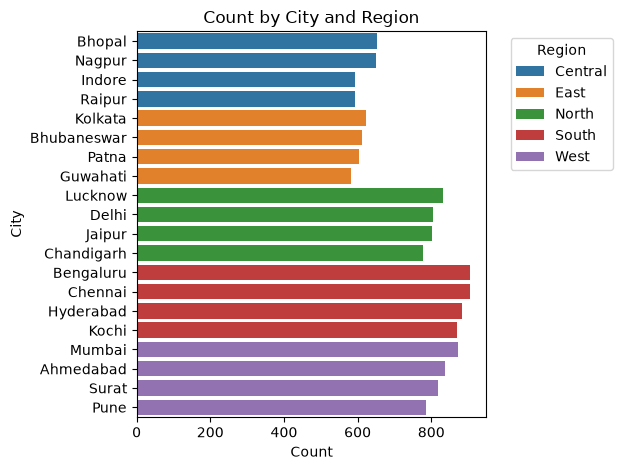

In [32]:
sns.barplot(
    data=group_region,
    x='count',
    y='City',
    hue='Region'
)

plt.title('Count by City and Region')
plt.xlabel('Count')
plt.ylabel('City')
plt.legend(title='Region', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [33]:
seg_to_reg = pd.DataFrame(df.groupby('Segment')['Region'].value_counts())

In [34]:
seg_to_reg

count
Segment        Region        
Consumer       South     1953
               West      1857
               North     1725
               East      1350
               Central   1339
Corporate      South      902
               North      860
               West       819
               Central    635
               East       591
Small Business South      706
               West       638
               North      632
               Central    515
               East       478

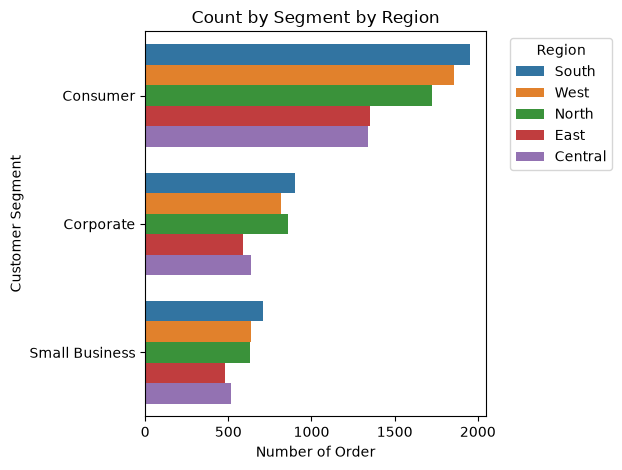

In [71]:
sns.barplot(
    data=seg_to_reg,
    x = 'count', 
    y = 'Segment',
    hue = 'Region'
)
plt.title("Count by Segment by Region")
plt.xlabel("Number of Order")
plt.ylabel('Customer Segment')
plt.legend(title='Region', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

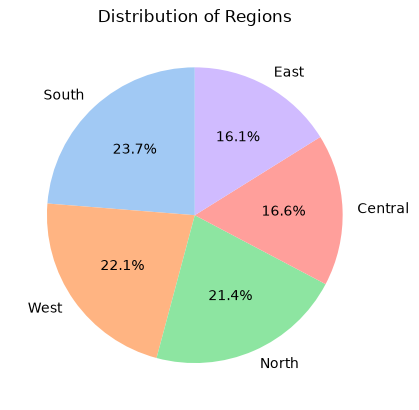

In [36]:
plt.pie(
    df['Region'].value_counts(),
    labels=df['Region'].value_counts().index,
    colors=sns.color_palette('pastel'),
    autopct='%.1f%%',
    startangle=90
)

plt.title('Distribution of Regions')
plt.show()

In [37]:
seg_to_city = pd.DataFrame(df.groupby('Segment')['City'].value_counts())

In [38]:
seg_to_city

count
Segment        City              
Consumer       Chennai        508
               Bengaluru      493
               Mumbai         489
               Hyderabad      485
               Ahmedabad      479
               Lucknow        470
               Kochi          467
               Pune           446
               Surat          443
               Jaipur         420
               Delhi          419
               Chandigarh     416
               Bhopal         356
               Bhubaneswar    351
               Patna          343
               Nagpur         340
               Kolkata        335
               Raipur         324
               Guwahati       321
               Indore         319
Corporate      Delhi          238
               Chennai        238
               Hyderabad      231
               Mumbai         222
               Bengaluru      219
               Jaipur         216
               Kochi          214
               Surat          212
               Chandigarh     203
               Lucknow        203
               Ahmedabad      195
               Pune           190
               Nagpur         170
               Kolkata        161
               Bhopal         160
               Indore         159
               Bhubaneswar    146
               Raipur         146
               Patna          143
               Guwahati       141
Small Business Bengaluru      192
               Kochi          188
               Hyderabad      168
               Jaipur         167
               Ahmedabad      164
               Surat          163
               Mumbai         161
               Lucknow        159
               Chennai        158
               Chandigarh     158
               Pune           150
               Delhi          148
               Nagpur         140
               Bhopal         136
               Kolkata        126
               Raipur         123
               Guwahati       119
               Patna          117
               Bhubaneswar    116
               Indore         116

In [39]:
cat_to_sub = pd.DataFrame(df.groupby('Category')['Subcategory'].value_counts())

In [40]:
cat_to_sub

count
Category        Subcategory         
Beauty          Personal Care    527
                Skincare         477
                Makeup           475
                Haircare         431
Furniture       Desks            740
                Tables           716
                Chairs           713
                Storage          690
Home & Kitchen  Appliances       680
                Decor            657
                Cookware         654
                Cleaning         651
Office Supplies Binders          884
                Paper            867
                Pens             823
                Printers         784
Technology      Laptops         1095
                Accessories     1077
                Phones          1040
                Monitors        1019

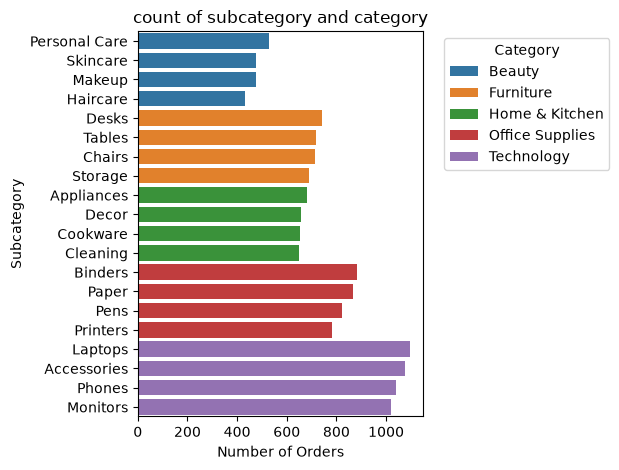

In [72]:
sns.barplot(
    data = cat_to_sub,
    x = 'count', 
    y = 'Subcategory',
    hue = 'Category'
)
plt.title('count of subcategory and category')
plt.xlabel("Number of Orders")
plt.ylabel("Subcategory")
plt.legend(title='Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


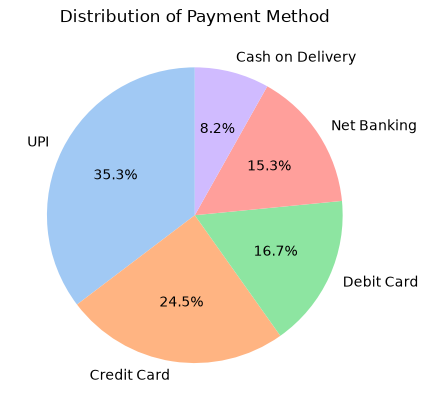

In [42]:
plt.pie(
    df['Payment_Method'].value_counts(),
    labels=df['Payment_Method'].value_counts().index,
    colors = sns.color_palette('pastel'),
    autopct='%.1f%%',
    startangle=90
)
plt.title('Distribution of Payment Method')
plt.show()

In [43]:
cat_to_payment = pd.DataFrame(df.groupby('Category')['Payment_Method'].value_counts())

In [44]:
cat_to_payment

count
Category        Payment_Method         
Beauty          UPI                 671
                Credit Card         467
                Debit Card          344
                Net Banking         287
                Cash on Delivery    141
Furniture       UPI                 961
                Credit Card         724
                Debit Card          488
                Net Banking         452
                Cash on Delivery    234
Home & Kitchen  UPI                 913
                Credit Card         640
                Debit Card          445
                Net Banking         414
                Cash on Delivery    230
Office Supplies UPI                1219
                Credit Card         829
                Debit Card          552
                Net Banking         514
                Cash on Delivery    244
Technology      UPI                1535
                Credit Card        1014
                Debit Card          679
                Net Banking         629
                Cash on Delivery    374

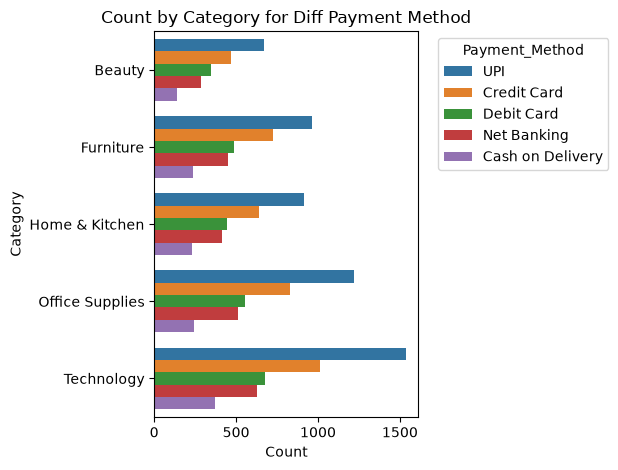

In [73]:
sns.barplot(
    data=cat_to_payment,
    x='count',
    y='Category',
    hue='Payment_Method'
)

plt.title('Count by Category for Diff Payment Method')
plt.xlabel('Count')
plt.ylabel('Category')
plt.legend(title='Payment_Method', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [46]:
payment_method_grp = df.groupby('Payment_Method',as_index=False)['Order_Year'].value_counts()

In [47]:
payment_method_grp

,Payment_Method,Order_Year,count
0,Cash on Delivery,2025,616
1,Cash on Delivery,2024,607
2,Credit Card,2025,1858
3,Credit Card,2024,1816
4,Debit Card,2025,1275
5,Debit Card,2024,1233
6,Net Banking,2025,1180
7,Net Banking,2024,1116
8,UPI,2024,2668
9,UPI,2025,2631


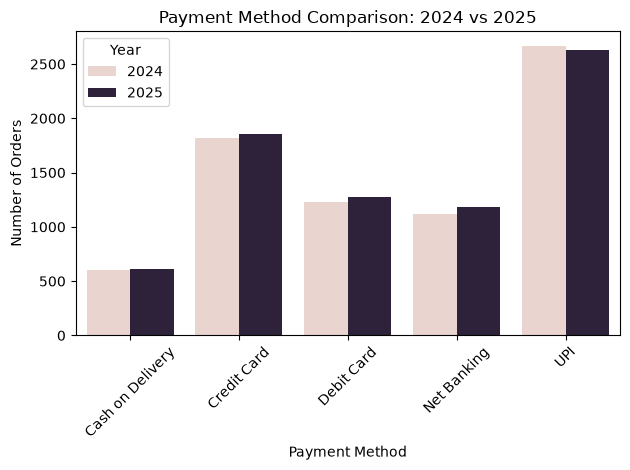

In [48]:
sns.barplot(
    data=payment_method_grp,
    x='Payment_Method',
    y='count',
    hue='Order_Year'
)

plt.title('Payment Method Comparison: 2024 vs 2025')
plt.xlabel('Payment Method')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.legend(title='Year')
plt.tight_layout()
plt.show()

In [49]:
payment_method_month = df.groupby('Payment_Method',as_index=False)['Order_month'].value_counts()

In [50]:
payment_method_month

,Payment_Method,Order_month,count
0,Cash on Delivery,1,115
1,Cash on Delivery,9,110
2,Cash on Delivery,4,110
3,Cash on Delivery,11,107
4,Cash on Delivery,6,106
5,Cash on Delivery,8,106
6,Cash on Delivery,12,103
7,Cash on Delivery,3,102
8,Cash on Delivery,10,102
9,Cash on Delivery,7,93


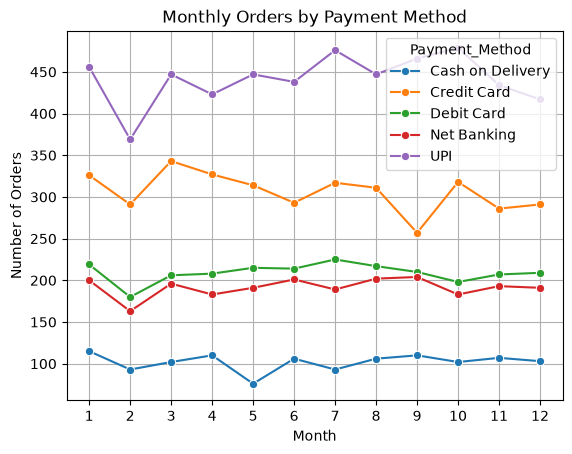

In [51]:
sns.lineplot(
    data=payment_method_month,
    x='Order_month',
    y='count',
    hue='Payment_Method',
    marker='o'
)

plt.title('Monthly Orders by Payment Method')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

In [52]:
Returned_grp = df.groupby('Category',as_index = False)['Returned'].value_counts()

In [53]:
Returned_grp

,Category,Returned,count
0,Beauty,No,1763
1,Beauty,Yes,147
2,Furniture,No,2654
3,Furniture,Yes,205
4,Home & Kitchen,No,2434
5,Home & Kitchen,Yes,208
6,Office Supplies,No,3128
7,Office Supplies,Yes,230
8,Technology,No,3926
9,Technology,Yes,305


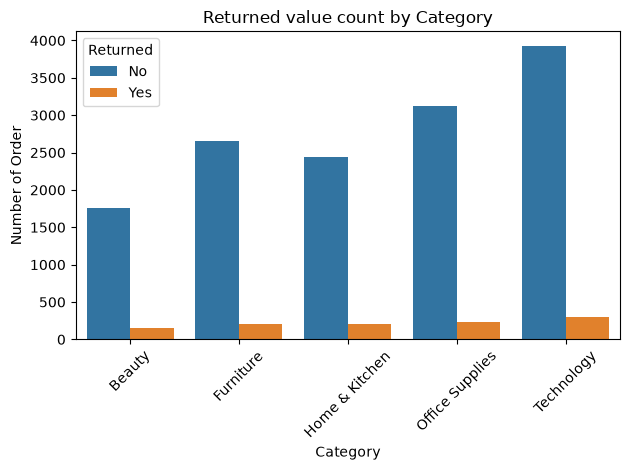

In [54]:
sns.barplot(
    data = Returned_grp, 
    x = 'Category', 
    y = 'count', 
    hue= 'Returned'
)
plt.title("Returned value count by Category")
plt.xlabel("Category")
plt.ylabel("Number of Order")
plt.xticks(rotation = 45)
plt.legend(title='Returned')
plt.tight_layout()
plt.show()

In [55]:
discount_grp = df.groupby('Category',as_index=False)['Discount_Amount_INR'].sum()

In [56]:
discount_grp

,Category,Discount_Amount_INR
0,Beauty,1109445.24
1,Furniture,1602782.96
2,Home & Kitchen,1501301.90
3,Office Supplies,2035521.22
4,Technology,2430919.63


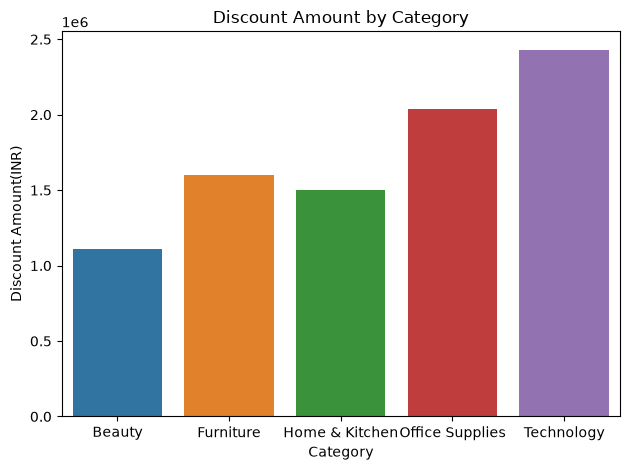

In [57]:
sns.barplot(
    data = discount_grp, 
    x = 'Category', 
    y = 'Discount_Amount_INR', 
    hue = 'Category', 
    legend=False
)
plt.title("Discount Amount by Category")
plt.xlabel("Category")
plt.ylabel("Discount Amount(INR)")
plt.xticks(rotation = 360)
plt.tight_layout()
plt.show()

In [58]:
profit_grp = df.groupby('Category',as_index=False)['Profit_INR'].sum()

In [59]:
profit_grp

,Category,Profit_INR
0,Beauty,4188832.22
1,Furniture,4923927.06
2,Home & Kitchen,4824401.96
3,Office Supplies,6956445.40
4,Technology,6384960.86


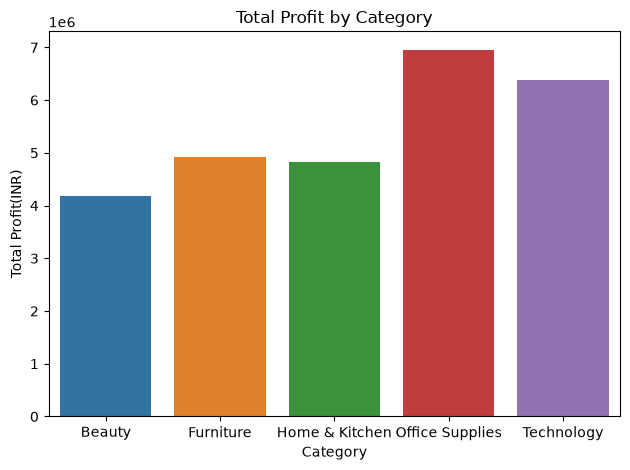

In [74]:
sns.barplot(
    data = profit_grp, 
    x = 'Category', 
    y = 'Profit_INR', 
    hue = 'Category', 
    legend = False
)
plt.title("Total Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit(INR)")
plt.tight_layout()
plt.show()

Unit_Price_INR       Axes(0.125,0.653529;0.227941x0.226471)
Quantity          Axes(0.398529,0.653529;0.227941x0.226471)
Discount          Axes(0.672059,0.653529;0.227941x0.226471)
Sales_INR            Axes(0.125,0.381765;0.227941x0.226471)
Net_Sales_INR     Axes(0.398529,0.381765;0.227941x0.226471)
Cost_INR          Axes(0.672059,0.381765;0.227941x0.226471)
Profit_INR               Axes(0.125,0.11;0.227941x0.226471)
Shipping_Days         Axes(0.398529,0.11;0.227941x0.226471)
dtype: object

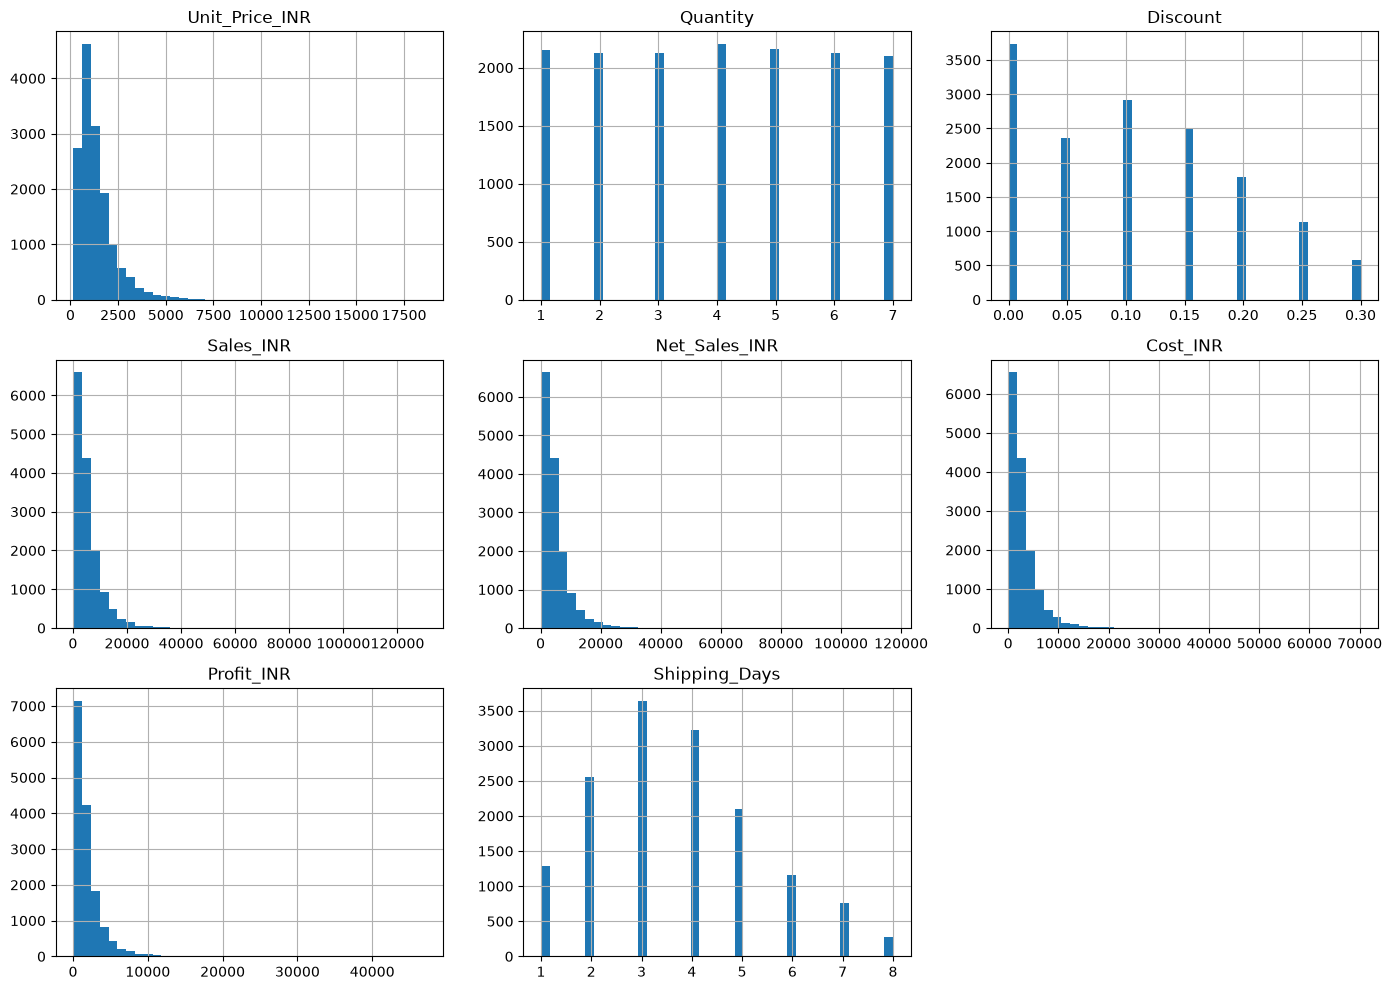

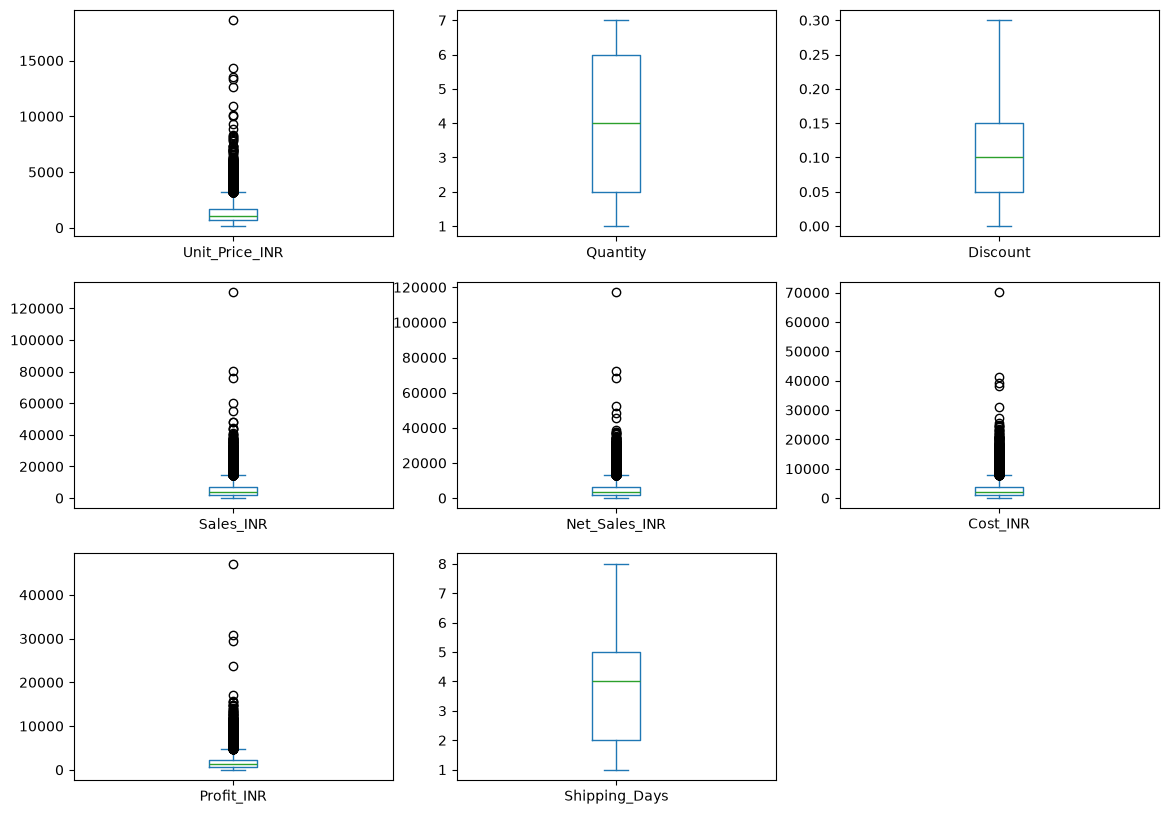

In [61]:
num_cols = ['Unit_Price_INR', 'Quantity', 'Discount', 'Sales_INR',
            'Net_Sales_INR', 'Cost_INR', 'Profit_INR', 'Shipping_Days']
df[num_cols].hist(figsize=(14, 10), bins=40)
plt.tight_layout()

df[num_cols].plot(kind='box', subplots=True, layout=(3, 3), figsize=(14, 10), sharex=False)

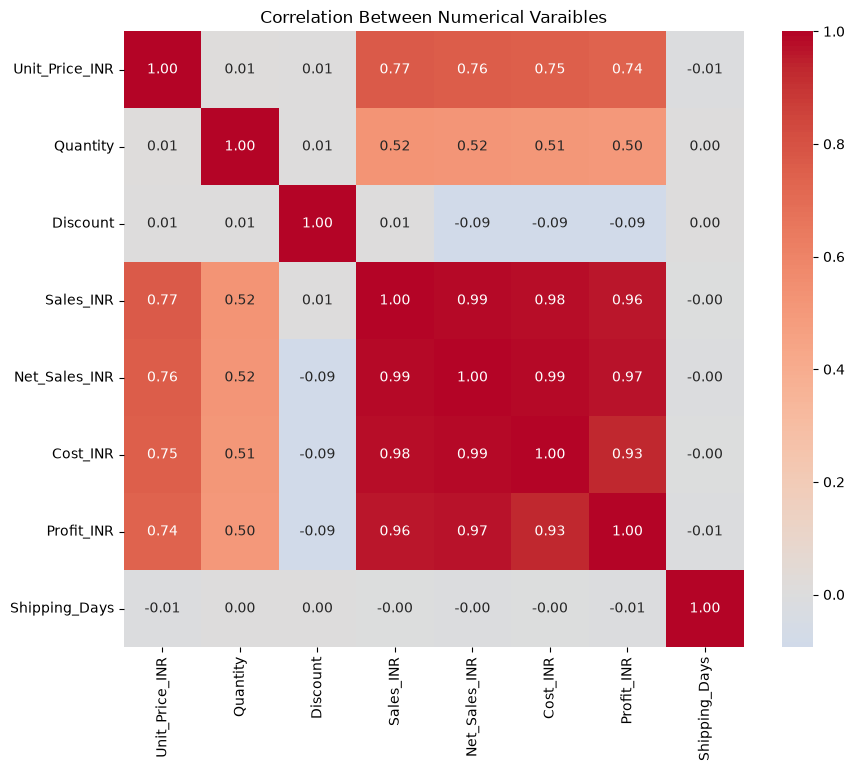

In [75]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title("Correlation Between Numerical Varaibles")
plt.show()


In [63]:
Channel_grp = df.groupby('Channel',as_index=False)['Category'].value_counts()

In [64]:
Channel_grp

,Channel,Category,count
0,Marketplace,Technology,792
1,Marketplace,Office Supplies,708
2,Marketplace,Furniture,589
3,Marketplace,Home & Kitchen,510
4,Marketplace,Beauty,382
5,Online,Technology,2460
6,Online,Office Supplies,1922
7,Online,Furniture,1658
8,Online,Home & Kitchen,1528
9,Online,Beauty,1132


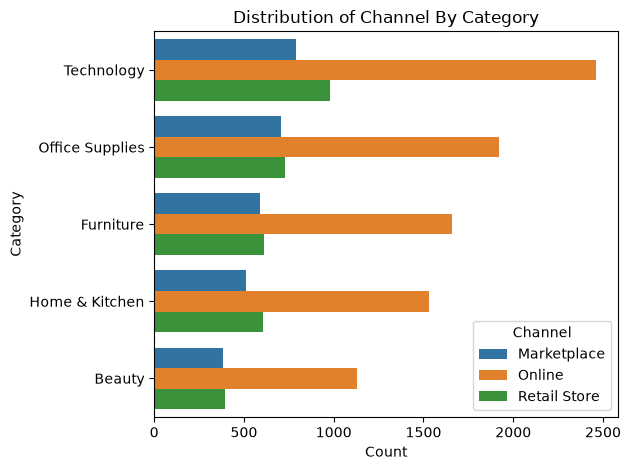

In [65]:
sns.barplot(
    data = Channel_grp, 
    x = 'count', 
    y = 'Category', 
    hue = 'Channel'
)
plt.title("Distribution of Channel By Category")
plt.xlabel("Count")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

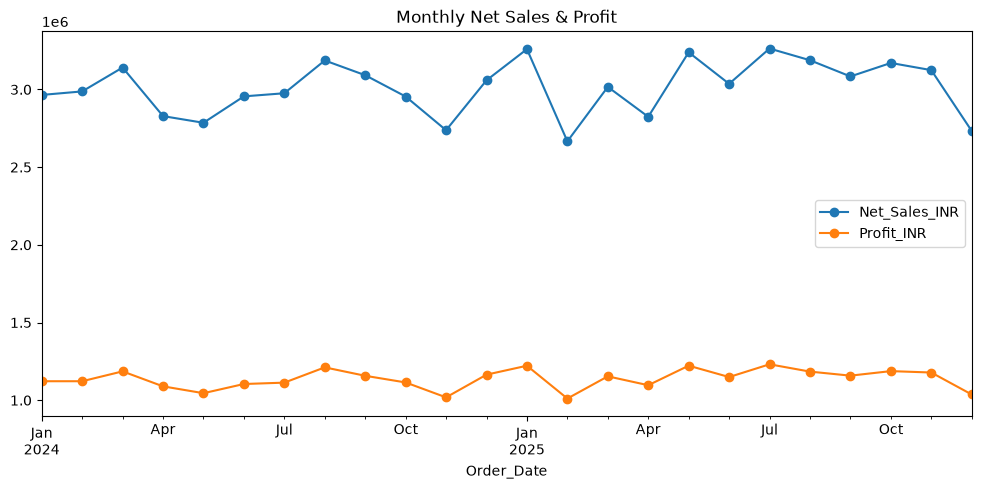

In [66]:
monthly = df.groupby(pd.Grouper(key='Order_Date', freq='ME'))[['Net_Sales_INR', 'Profit_INR']].sum()
monthly.plot(figsize=(12, 5), marker='o')
plt.title("Monthly Net Sales & Profit");

In [67]:
df.groupby('Channel')[['Net_Sales_INR', 'Profit_INR']].sum().sort_values('Net_Sales_INR')

,Net_Sales_INR,Profit_INR
Channel,,
Marketplace,14790156.47,5602262.81
Retail Store,15765302.67,5942910.81
Online,41716054.54,15733393.88


In [68]:
margin = df.groupby('Category').agg(
    sales=('Net_Sales_INR', 'sum'),
    profit=('Profit_INR', 'sum'),
)
margin['margin_%'] = margin['profit'] / margin['sales'] * 100

In [69]:
margin

,sales,profit,margin_%
Category,,,
Beauty,8938866.65,4188832.22,46.860887
Furniture,13649209.18,4923927.06,36.074816
Home & Kitchen,12629382.08,4824401.96,38.199826
Office Supplies,16562848.08,6956445.40,42.000297
Technology,20491207.69,6384960.86,31.159515


In [70]:
top_cities = df.groupby('City')['Net_Sales_INR'].sum().sort_values(ascending=False).head(10)


# EDA Analysis

## Feature Engineering
1. Order_Year (derived from Order_Date)
2. Order_month (derived from Order_Date)

## Key Findings

1. Consumer segment dominates order volume (8,224 / 15,000 = ~55%),
   but Corporate and Small Business collectively account for the rest.
2. South is the highest-volume region (3,561 orders), followed by West
   (3,314), North (3,217), Central (2,489), East (2,419).
3. Top 4 subcategories by order count are all in Technology
   (Laptops, Accessories, Phones, Monitors).
4. UPI is the dominant payment method at 35.3% of orders,
   used most heavily for Technology purchases.
5. UPI remains dominant in both 2024 and 2025 (~35% share each year),
   though its volume slightly declined YoY.
6. Technology accounts for the largest total discount (₹2.43M absolute),
   but this reflects high order volume — not necessarily high discount %.
7. Office Supplies is the most profitable category by absolute profit (₹6.96M),
   with Technology second (₹6.38M).
8. Online channel has the most orders (8,700), but revenue should be
   compared before concluding it "dominates the industry".
9. Correlation heatmap shows Discount has weak linear correlation
   with Profit (+0.13), and Shipping_Days is uncorrelated with
   Satisfaction (~0). Quantity is nearly uncorrelated with Sales
   — unit price dominates revenue.
10. Return rate is roughly uniform across all 5 categories (~7–8%),
    suggesting returns are not category-specific.